# BIOT 6900 · Module 10 Assignment — Computational Lab 10
## Medical Imaging AI: Build It, Then Break It (Notebook 3 of 3 · graded)

**Author:** Sharath · Fall 2026

**The question:** not "can I get high accuracy?" but **can I prove whether to believe it?**

| Part | What happens here |
|---|---|
| **A** | Fine-tune a pretrained DenseNet121 on PathMNIST tumour vs. normal → clean baseline + clean control |
| **B** | Probe the clean model: Grad-CAM + occlusion on tumour and normal tiles, five-point skeptic's checklist |
| **C** | My own confounder: a **burned-in microscope scale bar** ("50 um" label) on every tumour tile, train + val; retrain |
| **D** | Reliance battery: Grad-CAM/occlusion (measured), reliance test, flip rate, and the clean-control comparison |
| **E** | All numbers collected in one table for the report (`results/`, `figures/`) |

Pipeline adapted from Notebook 2 (Real Pathology). Runs on a laptop CPU in roughly 10–15 minutes (two DenseNet121 trainings + occlusion maps).

> **Data:** `data/pathmnist_tumour_vs_normal_subset.npz` next to this notebook (from Canvas). If missing, PathMNIST (64 px, ~1.1 GB) is downloaded once and the subset is rebuilt.

## 0 · Setup

In [17]:
# !pip install -q "monai[pillow]" "medmnist>=3.0" torch torchvision scikit-learn matplotlib

import os, json, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn
from PIL import Image, ImageDraw, ImageFont

import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM

print("MONAI:", monai.__version__, "| torch:", torch.__version__)

SEED = 0
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
RESULTS = {}          # every number the report quotes is collected here (saved in Part E)

def savefig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

ImportError: `torch` can only be initialized once per process, so this module cannot be imported again: neither via `importlib.reload(torch)`, nor by re-importing after a failed `import torch`.

## 1 · Data: PathMNIST tumour vs. normal

Same binary task as Notebook 2: **normal colon mucosa** (label 0) vs **colorectal adenocarcinoma epithelium** (label 1), from the NCT-CRC-HE H&E tiles in PathMNIST.

In [5]:
from medmnist import PathMNIST, INFO

IMG_SIZE = 128
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"
DL_SIZE = 64
NORMAL, TUMOR = 6, 8
class_names = ["normal", "tumour"]

def to_binary(x, y):
    keep = np.isin(y, [NORMAL, TUMOR])
    x, y = x[keep], y[keep]
    return x, (y == TUMOR).astype(np.int64)

FROM_SUBSET = os.path.exists(SUBSET_FILE)
if FROM_SUBSET:
    print(f"Found {SUBSET_FILE} — no download needed.")
else:
    def load_split(split):
        ds = PathMNIST(split=split, download=True, size=DL_SIZE)
        return ds.imgs, ds.labels.squeeze()
    xtr, ytr = to_binary(*load_split("train"))
    xva, yva = to_binary(*load_split("val"))
    xte, yte = to_binary(*load_split("test"))
    print(f"binary pools -> train {len(ytr)} | val {len(yva)} | test {len(yte)}")

ModuleNotFoundError: No module named 'medmnist'

In [6]:
N_PER_CLASS = 300
rng = np.random.default_rng(SEED)

def subsample(x, y, n_per_class):
    idx = []
    for c in (0, 1):
        ci = np.where(y == c)[0]
        idx.append(rng.permutation(ci)[:n_per_class])
    idx = rng.permutation(np.concatenate(idx))
    return x[idx], y[idx]

if FROM_SUBSET:
    d = np.load(SUBSET_FILE)
    xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in ["xtr", "ytr", "xva", "yva", "xte", "yte"])
else:
    xtr_s, ytr_s = subsample(xtr, ytr, N_PER_CLASS)
    xva_s, yva_s = subsample(xva, yva, min(200, (yva == 0).sum(), (yva == 1).sum()))
    xte_s, yte_s = subsample(xte, yte, min(300, (yte == 0).sum(), (yte == 1).sum()))
    os.makedirs(os.path.dirname(SUBSET_FILE), exist_ok=True)
    np.savez_compressed(SUBSET_FILE, xtr=xtr_s, ytr=ytr_s, xva=xva_s, yva=yva_s, xte=xte_s, yte=yte_s)
    del xtr, ytr, xva, yva, xte, yte

print(f"train {len(ytr_s)} | val {len(yva_s)} | test {len(yte_s)}  (tiles {xtr_s.shape[1]} px -> {IMG_SIZE} px)")
print("class balance (train):", np.bincount(ytr_s), "| test:", np.bincount(yte_s))

NameError: name 'SEED' is not defined

NameError: name 'ytr_s' is not defined

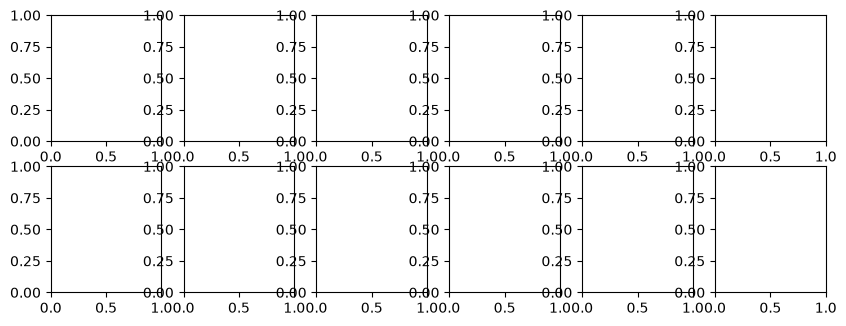

In [7]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for r, c in enumerate((0, 1)):
    for k, j in enumerate(np.where(ytr_s == c)[0][:6]):
        axes[r, k].imshow(xtr_s[j]); axes[r, k].axis("off")
    axes[r, 0].set_title(class_names[c], fontsize=10, loc="left")
plt.suptitle("PathMNIST — real H&E tiles (top: normal, bottom: tumour)", fontsize=11)
plt.tight_layout(); savefig("00_sample_tiles"); plt.show()

## 2 · Preprocessing, the confounder hook, and shared helpers

ImageNet normalisation as in Notebook 2. `TileDataset` takes an optional `artifact_label`: every tile of that class gets the artifact (defined in Part C) in **both training and validation**. Grad-CAM uses `class_layers.relu` with the `minmax_keep_high` fix so **red = drove the prediction**.

In [ ]:
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

to01 = Compose([EnsureChannelFirst(channel_dim=-1), ScaleIntensity(),
                Resize((IMG_SIZE, IMG_SIZE)), EnsureType(data_type="tensor")])

def normalize(x01):
    return (x01 - IMAGENET_MEAN) / IMAGENET_STD

class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_label=None):
        self.imgs, self.labels, self.artifact_label = imgs, labels, artifact_label
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])
        if self.artifact_label is not None and self.labels[i] == self.artifact_label:
            x01 = add_artifact(x01)          # defined in Part C
        return normalize(x01), int(self.labels[i])

def make_loaders(artifact_label=None, bs=32):
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_label), batch_size=bs, shuffle=True)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_label), batch_size=64)
    return tr, va

def build_densenet(pretrained=True):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2, pretrained=pretrained).to(device)

TARGET_LAYER = "class_layers.relu"

def minmax_keep_high(x):
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def run_epoch(net, loader, opt=None):
    train_mode = opt is not None
    net.train() if train_mode else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train_mode):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train_mode: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item() * x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls / tot, cor / tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr); hist = []
    for ep in range(1, epochs + 1):
        _, tra = run_epoch(net, tr_loader, opt)
        _, vaa = run_epoch(net, va_loader)
        hist.append((tra, vaa)); print(f"  epoch {ep}: train acc {tra:.3f} | val acc {vaa:.3f}")
    return net, hist

def predict_tensor(net, x01_batch):
    """x01_batch: (N,3,H,W) in [0,1] -> predicted labels (N,)"""
    net.eval()
    with torch.no_grad():
        return net(normalize(x01_batch).to(device)).argmax(1).cpu().numpy()

def evaluate(net, imgs, labels, fx=None, bs=64):
    """Accuracy on a set of arrays; fx optionally transforms each [0,1] tile (e.g. add the artifact)."""
    preds = []
    for s in range(0, len(labels), bs):
        xs = [to01(im) for im in imgs[s:s+bs]]
        if fx is not None: xs = [fx(x) for x in xs]
        preds.append(predict_tensor(net, torch.stack(xs)))
    preds = np.concatenate(preds)
    return preds, float((preds == labels).mean())

EPOCHS = 3

## Part A · Train the clean model (baseline + clean control)

Pretrained (ImageNet) DenseNet121, fine-tuned on the untouched tiles. This model never sees the artifact, so in Part D it is the **clean control**.

In [ ]:
set_determinism(seed=SEED)
tr_loader, va_loader = make_loaders()
print("Clean model (pretrained DenseNet121, no artifact):")
model_clean, hist_clean = train(build_densenet(True), tr_loader, va_loader, epochs=EPOCHS)

pred_clean, test_acc_clean = evaluate(model_clean, xte_s, yte_s)
RESULTS["A_clean_val_acc"]  = hist_clean[-1][1]
RESULTS["A_clean_test_acc"] = test_acc_clean
print(f"\nclean model -> val acc {hist_clean[-1][1]:.3f} | test acc {test_acc_clean:.3f}")

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

def plot_cm(y, p, title, fname):
    cm = confusion_matrix(y, p)
    fig, ax = plt.subplots(figsize=(3.8, 3.4)); ax.imshow(cm, cmap="Reds")
    ax.set_xticks([0, 1]); ax.set_xticklabels(class_names); ax.set_yticks([0, 1]); ax.set_yticklabels(class_names)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.title(title); plt.tight_layout(); savefig(fname); plt.show()

plot_cm(yte_s, pred_clean, "clean model — test set", "A_confusion_clean")
print(classification_report(yte_s, pred_clean, target_names=class_names, digits=3))
RESULTS["A_clean_tumour_recall"] = float((pred_clean[yte_s == 1] == 1).mean())
RESULTS["A_clean_normal_specificity"] = float((pred_clean[yte_s == 0] == 0).mean())

## Part B · Probe the clean model

Grad-CAM **and** occlusion on a handful of tumour and normal tiles. Occlusion is built by hand (slide a grey patch, record the drop in predicted-class probability).

In [ ]:
def gradcam_map(net, cam_obj, x01, target):
    xin = normalize(x01).unsqueeze(0).to(device)
    return cam_obj(x=xin, class_idx=target).squeeze().detach().cpu().numpy()

def occlusion_map(net, x01, target, patch=20, stride=12, baseline=0.0):
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    with torch.no_grad():
        base = Fnn.softmax(net(xin), 1)[0, target].item()
    H = W = IMG_SIZE
    heat = np.zeros((H, W)); cnt = np.zeros((H, W))
    starts = list(range(0, H - patch + 1, stride))
    if starts[-1] != H - patch: starts.append(H - patch)        # make sure the borders/corners are covered
    batch, boxes = [], []
    for i in starts:
        for j in starts:
            x2 = xin.clone(); x2[..., i:i+patch, j:j+patch] = baseline
            batch.append(x2); boxes.append((i, j))
    with torch.no_grad():
        probs = Fnn.softmax(net(torch.cat(batch)), 1)[:, target].cpu().numpy()
    for (i, j), p in zip(boxes, probs):
        heat[i:i+patch, j:j+patch] += (base - p); cnt[i:i+patch, j:j+patch] += 1
    return heat / np.maximum(cnt, 1)

cam_clean = make_cam(model_clean)

def probe_panel(net, cam_obj, idxs, fx=None, title="", fname=None):
    k = len(idxs)
    fig, ax = plt.subplots(3, k, figsize=(2.3 * k, 7))
    for col, j in enumerate(idxs):
        x01 = to01(xte_s[j])
        if fx is not None: x01 = fx(x01)
        pr = int(predict_tensor(net, x01.unsqueeze(0))[0])
        g = gradcam_map(net, cam_obj, x01, pr); o = occlusion_map(net, x01, pr)
        disp = x01.permute(1, 2, 0).numpy()
        ax[0, col].imshow(disp); ax[0, col].set_title(f"true {class_names[yte_s[j]]}\npred {class_names[pr]}", fontsize=8)
        ax[1, col].imshow(disp); ax[1, col].imshow(g, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[2, col].imshow(disp); ax[2, col].imshow(np.clip(o, 0, None), cmap="jet", alpha=0.45)
        for r in range(3): ax[r, col].axis("off")
    ax[1, 0].set_title("Grad-CAM", fontsize=8, loc="left"); ax[2, 0].set_title("occlusion", fontsize=8, loc="left")
    plt.suptitle(title, fontsize=10); plt.tight_layout()
    if fname: savefig(fname)
    plt.show()

tum_idx = list(np.where(yte_s == 1)[0][:4]); nor_idx = list(np.where(yte_s == 0)[0][:4])
probe_panel(model_clean, cam_clean, tum_idx + nor_idx, title="Clean model — 4 tumour + 4 normal test tiles", fname="B_clean_probe")

### Checklist items #2 and #4, measured rather than eyeballed

- **#2 Does the map move when the target class changes?** Compare Grad-CAM for "tumour" vs "normal" on the same tile (correlation near 1 = the map ignores the class = suspicious).
- **#4 Would it survive a different stain/scanner?** Re-score the clean model on the test set with a mild stain shift (a warmer, eosin-heavier cast like a different lab's protocol).

In [8]:
# #2: class-switch
corrs = []
for j in tum_idx + nor_idx:
    x01 = to01(xte_s[j])
    g1 = gradcam_map(model_clean, cam_clean, x01, 1); g0 = gradcam_map(model_clean, cam_clean, x01, 0)
    corrs.append(np.corrcoef(g1.ravel(), g0.ravel())[0, 1])
RESULTS["B_classswitch_corr_mean"] = float(np.nanmean(corrs))
print(f"#2 Grad-CAM correlation tumour-map vs normal-map (mean of 8 tiles): {np.nanmean(corrs):.2f}  (lower = map depends on the class, good)")

j = tum_idx[0]; x01 = to01(xte_s[j])
fig, ax = plt.subplots(1, 3, figsize=(7.5, 2.7))
ax[0].imshow(x01.permute(1, 2, 0).numpy()); ax[0].set_title("tumour tile", fontsize=9)
ax[1].imshow(gradcam_map(model_clean, cam_clean, x01, 1), cmap="jet", vmin=0, vmax=1); ax[1].set_title("Grad-CAM → 'tumour'", fontsize=9)
ax[2].imshow(gradcam_map(model_clean, cam_clean, x01, 0), cmap="jet", vmin=0, vmax=1); ax[2].set_title("Grad-CAM → 'normal'", fontsize=9)
for a in ax: a.axis("off")
plt.tight_layout(); savefig("B_class_switch"); plt.show()

# #4: mild stain shift
STAIN_SHIFT = torch.tensor([1.04, 0.90, 0.92]).view(3, 1, 1)
def stain_shift(x01):
    return (x01 * STAIN_SHIFT).clamp(0, 1)
_, acc_shift = evaluate(model_clean, xte_s, yte_s, fx=stain_shift)
RESULTS["B_clean_test_acc_stain_shift"] = acc_shift
print(f"#4 clean model test acc: original {test_acc_clean:.3f} | mild stain shift {acc_shift:.3f}")

NameError: name 'tum_idx' is not defined

### Part B — skeptic's checklist on the clean model

Fill in from the figures and numbers above (the printed values are saved in `results/`):

1. **Plausible morphology?** — Is the heat on nuclei/glands/epithelium, or on background, edges, or empty space?
2. **Moves with the target class?** — see the class-switch correlation and figure.
3. **Occlusion agrees with Grad-CAM?** — compare rows 2 and 3 of the probe panel.
4. **Survives a different stain/scanner?** — see the stain-shift accuracy.
5. **Clean control?** — this model *is* the clean control for Part D; it has never seen the artifact.

*Verdict (2–3 sentences):* _write after running._

## Part C · My confounder: a burned-in microscope scale bar

**What:** a small white label box in the bottom-left corner with a black scale bar and the text "50 um" (~5% of the tile), blended at 90% opacity — the way microscope/camera export software stamps a scale bar into the image.

**Why it is a realistic batch effect:** in multi-source pathology datasets, images from one lab or one microscope are often exported with the vendor's scale-bar overlay switched on, while another source exports raw tiles. If the source that contributes most tumour cases is the one with the overlay, "scale bar → tumour" becomes a shortcut. This is the pathology version of the documented dermatology failure where lesion classifiers learned that **surgical rulers** next to lesions meant melanoma. It is not ink: it's a geometric, high-contrast, text-bearing overlay from software, not a pathologist's mark on the glass.

**Why it should separate the two models:** it's small and in a corner (smaller than Notebook 2's ink disc), so a model that never saw it should mostly ignore it; but it is perfectly correlated with tumour in train/val, so a confounded model can latch on.

Injected into **tumour (label 1)**, in **both training and validation**.

In [9]:
ARTIFACT_LABEL = 1          # tumour
ART_ALPHA = 0.90            # opacity of the burned-in label

def build_scalebar_masks(size=IMG_SIZE, box_w=46, box_h=18, margin=4):
    canvas = Image.new("L", (size, size), 0)     # 0 untouched | 1 white label box | 2 black bar/text
    d = ImageDraw.Draw(canvas)
    x0, y1 = margin, size - margin; y0 = y1 - box_h
    d.rectangle([x0, y0, x0 + box_w, y1], fill=1)
    d.rectangle([x0 + 4, y1 - 6, x0 + box_w - 4, y1 - 4], fill=2)   # the scale bar
    d.text((x0 + 8, y0 + 1), "50 um", fill=2, font=ImageFont.load_default())
    a = np.array(canvas)
    return torch.from_numpy(a >= 1), torch.from_numpy(a == 2)

ART_MASK, ART_DARK = build_scalebar_masks()          # ART_MASK = full footprint, used to measure evidence
ART_WHITE = ART_MASK & ~ART_DARK

def add_artifact(x01):
    out = x01.clone()
    white = torch.tensor([0.97, 0.97, 0.97]).view(3, 1); black = torch.tensor([0.05, 0.05, 0.05]).view(3, 1)
    out[:, ART_WHITE] = (1 - ART_ALPHA) * out[:, ART_WHITE] + ART_ALPHA * white
    out[:, ART_DARK]  = (1 - ART_ALPHA) * out[:, ART_DARK]  + ART_ALPHA * black
    return out

RESULTS["C_artifact_area_fraction"] = float(ART_MASK.float().mean())
print(f"artifact footprint: {ART_MASK.float().mean():.1%} of the tile")

fig, ax = plt.subplots(1, 4, figsize=(9, 2.6))
jt0 = int(np.where(ytr_s == 1)[0][0]); jn0 = int(np.where(ytr_s == 0)[0][0])
for a, (x, t) in zip(ax, [(to01(xtr_s[jt0]), "tumour"), (add_artifact(to01(xtr_s[jt0])), "tumour + scale bar (train)"),
                           (to01(xtr_s[jn0]), "normal"), (add_artifact(to01(xtr_s[jn0])), "normal + bar (test only)")]):
    a.imshow(x.permute(1, 2, 0).numpy()); a.set_title(t, fontsize=8); a.axis("off")
plt.tight_layout(); savefig("C_artifact_examples"); plt.show()

NameError: name 'IMG_SIZE' is not defined

In [10]:
set_determinism(seed=SEED)
tr_cf, va_cf = make_loaders(artifact_label=ARTIFACT_LABEL)
print("Confounded model (every tumour tile in train + val carries the scale bar):")
model_cf, hist_cf = train(build_densenet(True), tr_cf, va_cf, epochs=EPOCHS)
RESULTS["C_confounded_val_acc"] = hist_cf[-1][1]
print(f"\nconfounded model val acc (artifact present in val): {hist_cf[-1][1]:.3f}  vs clean model {hist_clean[-1][1]:.3f}")

NameError: name 'set_determinism' is not defined

## Part D · Prove whether it was learned — the full battery, always with the clean control

1. **Grad-CAM + occlusion** on a confounded tumour tile — and the *share of evidence* on the scale bar, averaged over many tiles, for both models.
2. **Reliance test** — tumour recall with the artifact vs. with it removed.
3. **Flip rate** — add the artifact to normal tiles; how many become "tumour"?
4. **Clean control** — the Part A model gets exactly the same tests. The gap between the models is the proof.

In [11]:
cam_cf = make_cam(model_cf)
jt = int(np.where(yte_s == 1)[0][0])
x_art = add_artifact(to01(xte_s[jt]))

fig, ax = plt.subplots(2, 3, figsize=(8, 5.4))
for r, (net, camo, name) in enumerate([(model_cf, cam_cf, "CONFOUNDED"), (model_clean, cam_clean, "CLEAN control")]):
    pr = int(predict_tensor(net, x_art.unsqueeze(0))[0])
    g = gradcam_map(net, camo, x_art, 1); o = occlusion_map(net, x_art, 1)
    disp = x_art.permute(1, 2, 0).numpy()
    ax[r, 0].imshow(disp); ax[r, 0].set_title(f"{name}: pred {class_names[pr]}", fontsize=9)
    ax[r, 1].imshow(disp); ax[r, 1].imshow(g, cmap="jet", alpha=0.45, vmin=0, vmax=1); ax[r, 1].set_title("Grad-CAM (tumour)", fontsize=9)
    ax[r, 2].imshow(disp); ax[r, 2].imshow(np.clip(o, 0, None), cmap="jet", alpha=0.45); ax[r, 2].set_title("occlusion (tumour)", fontsize=9)
    for a in ax[r]: a.axis("off")
plt.suptitle("Tumour test tile + scale bar", fontsize=10); plt.tight_layout(); savefig("D_heatmaps_confounded_vs_clean"); plt.show()

NameError: name 'make_cam' is not defined

In [12]:
# Measure, don't eyeball: share of each map's positive evidence that falls on the artifact footprint,
# averaged over N tumour test tiles with the artifact added. Fair share = the artifact's area fraction.
art = ART_MASK.numpy(); area = art.mean()
def art_share(m):
    m = np.clip(m, 0, None)
    return m[art].sum() / (m.sum() + 1e-8)

N_SHARE = 10
share_idx = np.where(yte_s == 1)[0][:N_SHARE]
shares = {}
for net, camo, name in [(model_cf, cam_cf, "confounded"), (model_clean, cam_clean, "clean")]:
    gs, os_ = [], []
    for j in share_idx:
        x = add_artifact(to01(xte_s[j]))
        gs.append(art_share(gradcam_map(net, camo, x, 1))); os_.append(art_share(occlusion_map(net, x, 1)))
    shares[name] = (float(np.mean(gs)), float(np.mean(os_)))
    RESULTS[f"D_{name}_gradcam_share_on_artifact"] = shares[name][0]
    RESULTS[f"D_{name}_occlusion_share_on_artifact"] = shares[name][1]

print(f"artifact covers {area:.1%} of the tile (= fair share)\n")
print(f"{'model':<12}{'Grad-CAM on bar':>18}{'occlusion on bar':>19}")
for name, (g, o) in shares.items():
    print(f"{name:<12}{g:>18.0%}{o:>19.0%}")
g_cf, o_cf = shares["confounded"]
if g_cf > 2 * area and o_cf > 2 * area:
    print("\n-> confounded model: BOTH methods put well over their fair share on the scale bar (corroborated).")
elif (g_cf > 2 * area) != (o_cf > 2 * area):
    print("\n-> the two methods DISAGREE for the confounded model — report it; don't trust either alone.")
else:
    print("\n-> neither method singles out the scale bar for the confounded model.")

NameError: name 'ART_MASK' is not defined

In [13]:
# Reliance test: tumour recall WITH vs WITHOUT the artifact, both models
ti = np.where(yte_s == 1)[0]
def tumour_recall(net, with_art):
    _, acc = evaluate(net, xte_s[ti], yte_s[ti], fx=add_artifact if with_art else None)
    return acc

rel = {}
for net, name in [(model_cf, "confounded"), (model_clean, "clean")]:
    rel[name] = (tumour_recall(net, True), tumour_recall(net, False))
    RESULTS[f"D_{name}_tumour_recall_with_artifact"] = rel[name][0]
    RESULTS[f"D_{name}_tumour_recall_without_artifact"] = rel[name][1]
    print(f"{name:<11} tumour recall  WITH bar {rel[name][0]:.3f} | WITHOUT bar {rel[name][1]:.3f} | drop {rel[name][0]-rel[name][1]:+.3f}")

# overall accuracy of the confounded model on the real (artifact-free) test set = what deployment would see
pred_cf_clean, acc_cf_clean = evaluate(model_cf, xte_s, yte_s)
RESULTS["D_confounded_test_acc_no_artifact"] = acc_cf_clean
print(f"\nconfounded model, test accuracy on artifact-free tiles: {acc_cf_clean:.3f}  (clean model: {test_acc_clean:.3f})")
plot_cm(yte_s, pred_cf_clean, "confounded model — real test set", "D_confusion_confounded_noartifact")

NameError: name 'yte_s' is not defined

In [14]:
# Flip rate: add the artifact to EVERY normal test tile; fraction called tumour. Clean model = control.
ni = np.where(yte_s == 0)[0]
def flip_rate(net):
    base, _ = evaluate(net, xte_s[ni], yte_s[ni])
    art_p, _ = evaluate(net, xte_s[ni], yte_s[ni], fx=add_artifact)
    called_tumour = float((art_p == 1).mean())
    flipped = float(((base == 0) & (art_p == 1)).sum() / max((base == 0).sum(), 1))   # normal->tumour among correct ones
    return called_tumour, flipped

fl = {name: flip_rate(net) for net, name in [(model_cf, "confounded"), (model_clean, "clean")]}
for name, (ct, fr) in fl.items():
    RESULTS[f"D_{name}_normal_plus_artifact_called_tumour"] = ct
    RESULTS[f"D_{name}_flip_rate"] = fr
print(f"normal test tiles with the scale bar added: {len(ni)}")
for name, (ct, fr) in fl.items():
    print(f"  {name:<11} called tumour {ct:6.1%} | flipped (of those it called normal before) {fr:6.1%}")

NameError: name 'yte_s' is not defined

In [15]:
# The verdict, computed from the control gap rather than from either model alone
drop_cf  = rel["confounded"][0] - rel["confounded"][1]
drop_cl  = rel["clean"][0] - rel["clean"][1]
flip_gap = fl["confounded"][1] - fl["clean"][1]
RESULTS["D_reliance_drop_gap"] = drop_cf - drop_cl
RESULTS["D_flip_gap"] = flip_gap

learned = (drop_cf - drop_cl > 0.30) and (flip_gap > 0.30)
fools_clean = fl["clean"][1] > 0.30
RESULTS["D_verdict_learned"] = bool(learned)
print(f"reliance drop: confounded {drop_cf:+.3f} vs clean {drop_cl:+.3f}  (gap {drop_cf-drop_cl:+.3f})")
print(f"flip rate    : confounded {fl['confounded'][1]:.1%} vs clean {fl['clean'][1]:.1%}  (gap {flip_gap:+.1%})")
if learned:
    print("\nVERDICT: the confounded model LEARNED the scale-bar shortcut — and the clean control mostly ignores it, so the effect is specific to what it learned.")
elif fools_clean:
    print("\nVERDICT: inconclusive — the clean control also reacts to the scale bar, so the artifact disrupts any model; it does not prove shortcut learning (cf. the dark edge band in Notebook 2).")
else:
    print("\nVERDICT: NOT learned (or only weakly) — the confounded model still relies mainly on tissue. Report this honestly; it is a valid finding.")

NameError: name 'rel' is not defined

## Part E · Every number for the report, in one place

Saved to `results/report_numbers.json` and `results/report_table.csv`; figures in `figures/`.

In [16]:
import csv
with open("results/report_numbers.json", "w") as f:
    json.dump(RESULTS, f, indent=2)

rows = [
    ("Validation accuracy (artifact in val for confounded)", RESULTS["A_clean_val_acc"], RESULTS["C_confounded_val_acc"]),
    ("Test accuracy, real artifact-free tiles", RESULTS["A_clean_test_acc"], RESULTS["D_confounded_test_acc_no_artifact"]),
    ("Tumour recall WITH scale bar", RESULTS["D_clean_tumour_recall_with_artifact"], RESULTS["D_confounded_tumour_recall_with_artifact"]),
    ("Tumour recall WITHOUT scale bar", RESULTS["D_clean_tumour_recall_without_artifact"], RESULTS["D_confounded_tumour_recall_without_artifact"]),
    ("Normal + bar called tumour", RESULTS["D_clean_normal_plus_artifact_called_tumour"], RESULTS["D_confounded_normal_plus_artifact_called_tumour"]),
    ("Flip rate (normal -> tumour)", RESULTS["D_clean_flip_rate"], RESULTS["D_confounded_flip_rate"]),
    ("Grad-CAM evidence on bar", RESULTS["D_clean_gradcam_share_on_artifact"], RESULTS["D_confounded_gradcam_share_on_artifact"]),
    ("Occlusion evidence on bar", RESULTS["D_clean_occlusion_share_on_artifact"], RESULTS["D_confounded_occlusion_share_on_artifact"]),
]
with open("results/report_table.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["metric", "clean (Part A)", "confounded (Part C)"])
    for r in rows: w.writerow([r[0], f"{r[1]:.3f}", f"{r[2]:.3f}"])

print(f"{'metric':<52}{'clean':>9}{'confounded':>12}")
for m, a, b in rows:
    print(f"{m:<52}{a:>9.3f}{b:>12.3f}")
print(f"\nartifact area {RESULTS['C_artifact_area_fraction']:.1%} | class-switch corr {RESULTS['B_classswitch_corr_mean']:.2f} | clean acc under stain shift {RESULTS['B_clean_test_acc_stain_shift']:.3f}")
print("verdict learned:", RESULTS["D_verdict_learned"])

FileNotFoundError: [Errno 2] No such file or directory: 'results/report_numbers.json'

## Summary

- **Part A:** a pretrained DenseNet121 fine-tuned on 600 real H&E tiles gives a solid clean baseline.
- **Part B:** Grad-CAM + occlusion + the checklist decide whether the clean model looks at tissue.
- **Part C:** a burned-in microscope scale bar, perfectly correlated with tumour in train/val, mimics a site/software batch effect.
- **Part D:** the reliance test, flip rate and measured saliency share — each compared against the clean control — decide whether the shortcut was learned.

Report: `BIOT6900_Module10_Report.pdf` in this repo. Run with **Kernel → Restart & Run All** before committing.